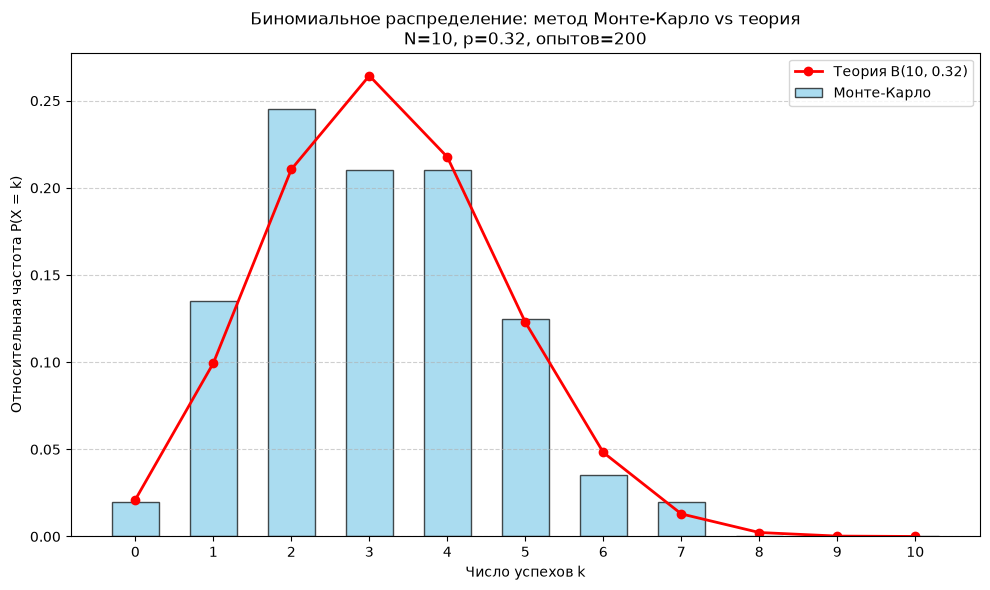

In [32]:
import random
import matplotlib.pyplot as plt
import math

def MonteCarloBinomial(num_experiments, N_trials, p):
    """
    num_experiments - количество проводимых опытов (сколько раз мы повторяем N_trials испытаний)
    N_trials        - число испытаний Бернулли в одном опыте (параметр N биномиального распределения)
    p               - вероятность успеха в одном испытании (параметр p биномиального распределения)
    """
    experiments = []
    
    # 1. Моделируем num_experiments значений биномиальной СВ
    for _ in range(num_experiments):
        successes = 0
        for _ in range(N_trials):
            if random.random() < p:   
                successes += 1
        experiments.append(successes)
    
    # 2. Возможные значения биномиальной СВ: 0, 1, 2, ..., N_trials
    segments = list(range(N_trials + 1))
    results = [0] * (N_trials + 1)
    
    # 3. Подсчитываем попадания в каждый сегмент (значение)
    for value in experiments:
        results[value] += 1
    
    # 4. Относительная частота = число встреч / num_experiments
    y_values = [count / num_experiments for count in results]
    
    return segments, y_values, experiments


# === Параметры эксперимента ===
num_experiments = 200   # сколько раз повторяем опыт
N_trials = 10             # число испытаний Бернулли в одном опыте
p = 0.32                   # вероятность успеха

segments, y_values, experiments = MonteCarloBinomial(num_experiments, N_trials, p)


# === Теоретическая биномиальная кривая (для сравнения) ===
def binomial_pmf(k, N, p):
    """Формула биномиального распределения: P(X=k) = C(N,k) * p^k * (1-p)^(N-k)"""
    C = math.comb(N, k)
    return C * (p ** k) * ((1 - p) ** (N - k))

y_theory = [binomial_pmf(k, N_trials, p) for k in segments]

mc1 = experiments

# === Визуализация ===
plt.figure(figsize=(10, 6))
plt.bar(segments, y_values, width=0.6, color='skyblue', 
        edgecolor='black', alpha=0.7, label='Монте-Карло')
plt.plot(segments, y_theory, 'ro-', linewidth=2, markersize=6, 
         label=f'Теория B({N_trials}, {p})')
plt.xlabel('Число успехов k')
plt.ylabel('Относительная частота P(X = k)')
plt.title(f'Биномиальное распределение: метод Монте-Карло vs теория\n'
          f'N={N_trials}, p={p}, опытов={num_experiments}')
plt.xticks(segments)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


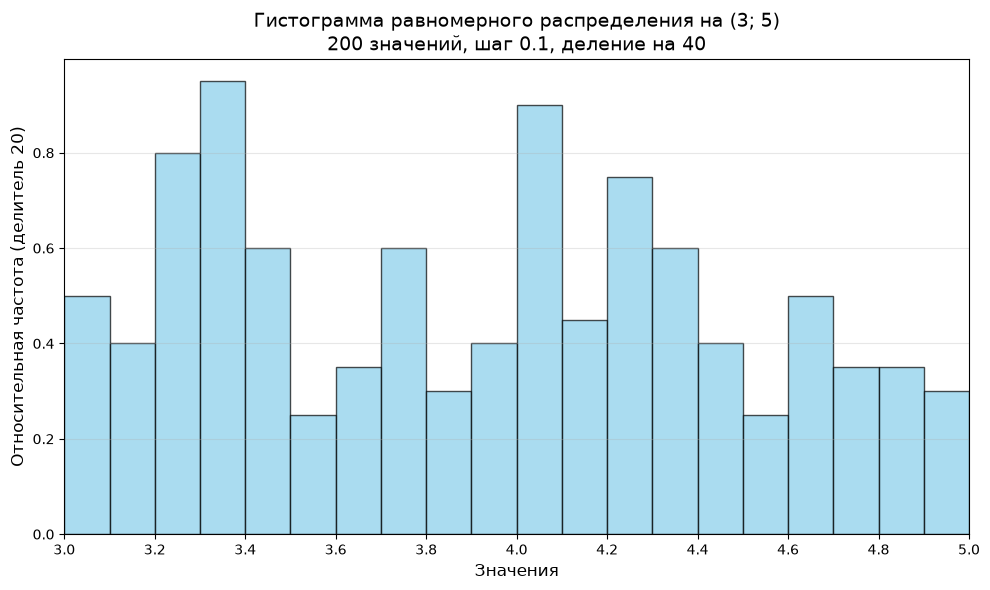

Сгенерировано 200 значений
Минимум: 3.0293, Максимум: 4.9661
Среднее: 3.9228 (теоретическое: 4.0)


In [29]:
import random
import matplotlib.pyplot as plt
import numpy as np

def generate_uniform_sample(a=3.0, b=5.0, n=200):
    """
    Генерирует n значений равномерного распределения на интервале (a, b)
    стандартным методом (методом обратной функции).
    """
    return [a + (b - a) * random.random() for _ in range(n)]

# Генерируем выборку
sample = generate_uniform_sample()

# Параметры для гистограммы
a, b = 3.0, 5.0
bin_width = 0.1
bins = np.arange(a, b + bin_width, bin_width)

mc2 = sample

# Создаем гистограмму
# Делим на 40 вместо 200 для оси Y
plt.figure(figsize=(10, 6))
plt.hist(sample, bins=bins, weights=np.ones(len(sample)) / (5*4), 
         edgecolor='black', alpha=0.7, color='skyblue')

plt.xlabel('Значения', fontsize=12)
plt.ylabel('Относительная частота (делитель 20)', fontsize=12)
plt.title('Гистограмма равномерного распределения на (3; 5)\n200 значений, шаг 0.1, деление на 40', 
          fontsize=14)
plt.grid(axis='y', alpha=0.3)
plt.xlim(a, b)
plt.xticks(np.arange(a, b + 0.2, 0.2))

plt.tight_layout()
plt.show()

print(f"Сгенерировано {len(sample)} значений")
print(f"Минимум: {min(sample):.4f}, Максимум: {max(sample):.4f}")
print(f"Среднее: {sum(sample)/len(sample):.4f} (теоретическое: {(a+b)/2})")

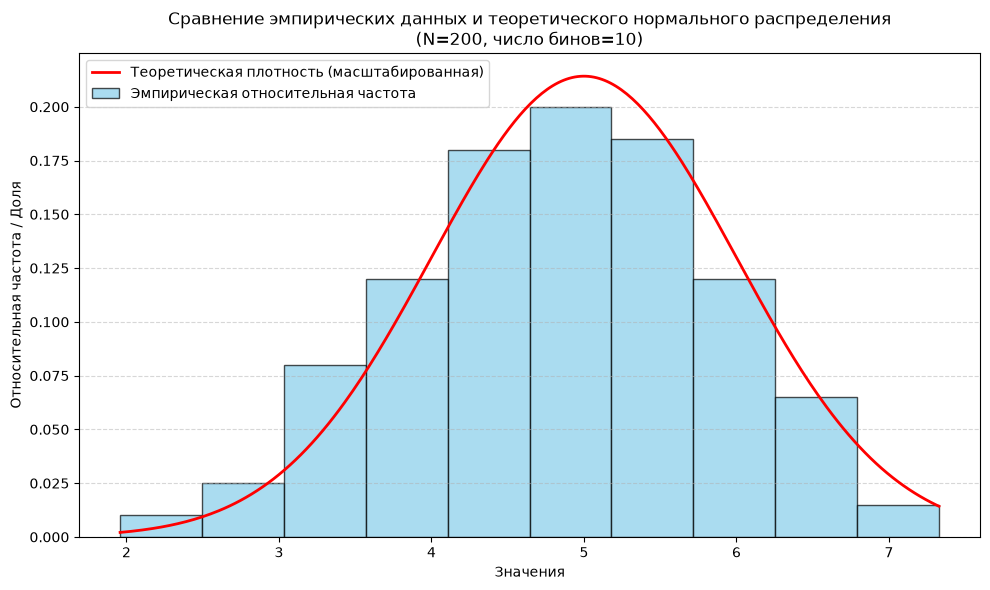

Число отрезков N = 10
Ширина отрезка = 0.5370
----------------------------------------
Центр      | Отн. частота    | Теор. доля
2.227      | 0.0100          | 0.0046    
2.764      | 0.0250          | 0.0177    
3.301      | 0.0800          | 0.0510    
3.838      | 0.1200          | 0.1099    
4.375      | 0.1800          | 0.1771    
4.912      | 0.2000          | 0.2132    
5.449      | 0.1850          | 0.1942    
5.986      | 0.1200          | 0.1324    
6.523      | 0.0650          | 0.0675    
7.060      | 0.0150          | 0.0257    


In [30]:
from random import random
import matplotlib.pyplot as plt
import math
import numpy as np

# --- Параметры ---
m = 5
sigma = 1
n = 200
N_bins = 2*int(math.log(n))  # N = 2*[log(200)] = 2*5=10

# --- 1. Генерация данных (исправленная) ---
numbers = []
for _ in range(n):
    x = 0
    for _ in range(12):
        x += random()
    x -= 6  # Центрирование суммы 12 равномерных величин
    numbers.append(sigma * x + m)

# --- 2. Разбиение на отрезки и подсчет частот ---
min_val = min(numbers)
max_val = max(numbers)
bin_width = (max_val - min_val) / N_bins

# Границы отрезков
bin_edges = [min_val + i * bin_width for i in range(N_bins + 1)]

# Подсчет попаданий
counts = [0] * N_bins
for val in numbers:
    idx = int((val - min_val) / bin_width)
    if idx >= N_bins:
        idx = N_bins - 1
    counts[idx] += 1

# Относительные частоты (доля от общего числа)
rel_freq = [c / n for c in counts]

# Середины отрезков для графика
bin_centers = [(bin_edges[i] + bin_edges[i+1]) / 2 for i in range(N_bins)]

# --- 3. Теоретическая кривая (Нормальное распределение) ---
# Создаем плавный массив точек для построения линии
x_theory = np.linspace(min_val, max_val, 300)

# Функция плотности нормального распределения
def normal_pdf(x, mu, sigma):
    return (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu) / sigma)**2)

y_theory_pdf = normal_pdf(x_theory, m, sigma)

# ВАЖНО: 
# rel_freq — это доля значений в бине (сумма = 1).
# PDF интегрируется в 1. 
# Чтобы сравнить высоту столбца (доля) с кривой, нужно умножить PDF на ширину бина.
# Тогда значение кривой покажет "ожидаемую долю" в данном интервале.
y_theory_scaled = y_theory_pdf * bin_width

# --- 4. Построение графика ---
plt.figure(figsize=(10, 6))

# Столбчатая диаграмма (эмпирические данные)
plt.bar(bin_centers, rel_freq, width=bin_width, color='skyblue', edgecolor='black', alpha=0.7, label='Эмпирическая относительная частота')

# Теоретическая кривая
plt.plot(x_theory, y_theory_scaled, color='red', linewidth=2, label='Теоретическая плотность (масштабированная)')

plt.xlabel("Значения")
plt.ylabel("Относительная частота / Доля")
plt.title(f"Сравнение эмпирических данных и теоретического нормального распределения\n(N={n}, число бинов={N_bins})")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

mc3 = numbers

# Вывод таблицы для проверки
print(f"Число отрезков N = {N_bins}")
print(f"Ширина отрезка = {bin_width:.4f}")
print("-" * 40)
print(f"{'Центр':<10} | {'Отн. частота':<15} | {'Теор. доля':<10}")
for i in range(N_bins):
    print(f"{bin_centers[i]:<10.3f} | {rel_freq[i]:<15.4f} | {y_theory_scaled[np.argmin(np.abs(x_theory - bin_centers[i]))]:<10.4f}")

In [ ]:
#Проверка успешности инициализации экспериментов 1-3 лабораторной работы
print(mc1)
print(mc2)
print(mc3)

#Обработка первого эксперимента
print("Первая лабораторная работа")

print("Математическое ожидание для биномиального распределения: M(сл. в.) = n * p")
m_true = 10 * 0.32
print("Теоретическое мат. ожидание", m_true)

print("Дисперсия для биномиального распределения: D = n * p * q, q = 1 - p")
D_true = 10 * 0.32 * (1 - 0.32)
print("Теоретическая дисперсия: ",D_true)

x_mark = 0
for x in mc1:
    x_mark += x
x_mark = x_mark / len(mc1)
print("Оценка математического ожидания: ", x_mark)

D_mark = 0
for d in mc1

[5, 3, 6, 4, 5, 2, 1, 3, 3, 4, 2, 2, 1, 1, 1, 4, 6, 3, 3, 2, 4, 5, 1, 2, 5, 3, 4, 2, 3, 6, 1, 4, 1, 3, 5, 2, 2, 7, 3, 2, 4, 1, 2, 2, 4, 2, 4, 2, 3, 4, 2, 2, 3, 5, 0, 1, 3, 3, 4, 4, 3, 2, 3, 5, 2, 3, 3, 4, 2, 2, 5, 2, 4, 3, 1, 3, 5, 3, 3, 2, 2, 2, 1, 6, 2, 3, 4, 7, 2, 5, 1, 4, 6, 3, 4, 4, 4, 5, 2, 4, 2, 3, 4, 3, 5, 1, 3, 4, 2, 2, 2, 3, 5, 5, 4, 2, 6, 1, 4, 4, 2, 6, 1, 1, 2, 4, 5, 2, 3, 3, 3, 5, 3, 5, 1, 0, 4, 3, 2, 2, 5, 1, 3, 3, 3, 3, 1, 7, 4, 4, 3, 2, 5, 4, 4, 0, 2, 4, 4, 2, 2, 0, 1, 1, 4, 2, 4, 2, 3, 4, 2, 5, 5, 2, 5, 1, 4, 3, 3, 1, 2, 5, 3, 4, 4, 5, 4, 4, 2, 5, 7, 2, 1, 1, 1, 3, 2, 1, 4, 2]
[3.369298780384872, 3.204336675160065, 3.549100198772517, 4.129355728846188, 4.3043724571415165, 3.481411769273481, 3.9560108157157234, 3.032797959711305, 4.045721099592237, 3.791060846152617, 4.609599893696327, 3.2061588280155933, 3.748131176257682, 4.473724645972643, 3.7348915231555457, 4.71137628263376, 3.9465306277449548, 3.351379913772193, 4.247057223593361, 3.393544888049527, 3.406439020790

In [ ]:
n = 1000
s = 0
for i in range(0, n):
    s += 